# Host size and listing performance in Broward
## Where can independent Airbnb hosts compete with professionals?

**Question:** Is host portfolio size associated with estimated revenue per bedroom and occupancy, what listing characteristics explain those differences, and where do single-listing hosts outperform professional accounts?

| Section | Question | Evidence |
|---|---|---|
| 1 | What can these data tell us? | Definitions, sample audit, formula checks |
| 2 | Who performs better before adjustment? | Host/listing shares, distributions, host-weighted benchmarks |
| 3 | Does host size matter among comparable listings? | Host-clustered regressions, two-part occupancy analysis |
| 4 | What listing traits predict performance? | Host-separated validation, linear/tree/forest comparisons, permutation importance |
| 5 | Where do independents beat pros? | Common-support comparisons and segment gaps with uncertainty |
| 6 | Do the findings survive alternative choices? | Host definitions, sample restrictions, panel and calendar checks |
| 7 | What should an independent host take away? | Evidence-based recommendations and limitations |

**Scope:** Broward County, not all of Miami or South Florida. Main sample: September 22, 2026 snapshot, `analysis_ready == 1`. Each listing appears once. “Independent” means **single-listing account** in the main comparisons; small hosts (2–9) remain a separate group. Pro means 10+ listings across all markets, not a verified professional credential.

This notebook follows the example's question → method → evidence → interpretation structure. It uses only `listings_panel.parquet` and `calendar_monthly.parquet`; review text, property sales, mortgage rates, and Zillow prices are unnecessary for this performance question.

### Run instructions
Place this notebook beside the parquet files, or in your project's `notebooks/` folder with files in `../data/processed/`. Alternatively set the `AIRBNB_DATA_DIR` environment variable. Outputs are embedded; **Restart Kernel and Run All** reproduces them.

Dependencies: Python 3.10+, pandas, numpy, pyarrow, matplotlib, scipy, statsmodels, scikit-learn, IPython. If needed, run `%pip install pandas numpy pyarrow matplotlib scipy statsmodels scikit-learn` in a separate cell. Random seeds are fixed. No web calls or external datasets are required.

In [1]:
import os, json, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown
import scipy, sklearn, statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score
SEED = 6211
TIERS = ['single', 'small (2-9)', 'pro (10+)']
COLORS = ['#237A8A', '#D59538', '#81589B']
SEP, DEC, JUN = map(pd.Timestamp, ['2026-09-22', '2025-12-28', '2026-06-29'])
paths = [Path(os.environ['AIRBNB_DATA_DIR'])] if os.environ.get('AIRBNB_DATA_DIR') else [Path('.'), Path('data/processed'), Path('../data/processed'), Path('upload')]
DATA = next((p for p in paths if (p/'listings_panel.parquet').exists()), None)
if DATA is None:
    raise FileNotFoundError('Set AIRBNB_DATA_DIR or place the parquet files beside the notebook.')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlepad': 12})
listings = pd.read_parquet(DATA/'listings_panel.parquet')
assert not listings.duplicated(['id','snapshot_date']).any()
print('Data directory:', DATA.resolve())
print({k:v for k,v in [('Python',platform.python_version()),('pandas',pd.__version__),('sklearn',sklearn.__version__),('statsmodels',statsmodels.__version__)]})

Data directory: /workspace/scratch/17c8d0345871/upload
{'Python': '3.12.14', 'pandas': '2.2.3', 'sklearn': '1.8.0', 'statsmodels': '0.15.0'}


## 1. Define the outcomes before comparing hosts

These are **estimated performance measures, not booked revenue or audited occupancy**:

- Estimated occupied nights = min(255, 2 × last-12-month reviews × max(minimum nights, 3)).
- Estimated annual revenue = scrape-day nightly price × estimated occupied nights.
- Revenue per bedroom = estimated annual revenue / max(bedrooms, 1). Studios use one bedroom equivalent.
- Occupancy = estimated occupied nights / 365. The imposed ceiling is 69.9%, not full occupancy.

The September estimate roughly covers October 2025–September 2026, but uses September's asking price for the whole year. Zero estimates remain in the main sample. They include idle and newly listed properties; they do not necessarily mean no bookings.

**Leakage rule:** price, review counts, minimum stay, availability, and outcome-derived flags never enter the main explanatory or predictive feature set. Minimum stay and quality flags may define sample restrictions. Ratings are analyzed only where observed; Superhost and ratings are secondary associations, since good performance can produce them. Bedroom count is a valid control but also the revenue-per-bedroom denominator, so its coefficient has a partly mechanical interpretation.

In [2]:
audit = listings.groupby('snapshot_date').agg(listings=('id','size'), hosts=('host_id','nunique'), analysis_ready=('analysis_ready','sum'), missing_price=('price',lambda s:s.isna().sum()))
display(audit)
sep = listings.loc[listings.snapshot_date.eq(SEP)].copy()
flow = pd.DataFrame({'stage':['All September listings','Bookable','Also no price outlier','Also short term: analysis_ready'],
                     'listings':[len(sep),sep.bookable.eq(1).sum(),(sep.bookable.eq(1)&sep.price_outlier.eq(0)).sum(),sep.analysis_ready.eq(1).sum()]})
display(flow)
d = sep.loc[sep.analysis_ready.eq(1)].copy()
assert d.id.is_unique and d.host_id.notna().all()
assert d[['revenue_per_bedroom','occupancy_rate_l365d','bedrooms']].notna().all().all()
assert d.host_tier.isin(TIERS).all()
assert d.groupby('host_id',observed=True).host_tier.nunique().max() == 1
print('Zero estimated occupancy:', int(d.zero_occupancy.sum()), '| Capped:', int(d.occupancy_capped.sum()))
print('Bedroom values filled by preprocessing:', int(d.bedrooms_was_filled.sum()))
display(d.groupby('host_tier',observed=True).agg(n=('id','size'),zero_share=('zero_occupancy','mean'),cap_share=('occupancy_capped','mean'),bedrooms_filled=('bedrooms_was_filled','mean')))
valid = d.minimum_nights.notna()
formula_occ = np.minimum(255, 2*d.loc[valid,'number_of_reviews_ltm']*np.maximum(d.loc[valid,'minimum_nights'],3))
print('Occupancy formula agreement on known minimum stays:', np.isclose(formula_occ,d.loc[valid,'estimated_occupancy_l365d']).mean())
print('Rows excluded from that formula check:', int((~valid).sum()))
assert np.allclose(d.estimated_revenue_l365d, d.price*d.estimated_occupancy_l365d, atol=0.51, rtol=0)
print("Revenue formula agrees within $0.50 rounding.")
assert np.allclose(d.revenue_per_bedroom,d.estimated_revenue_l365d/d.bedrooms.clip(lower=1))
assert d.occupancy_rate_l365d.between(0,255/365+1e-9).all()

Zero estimated occupancy: 4331 | Capped: 807
Bedroom values filled by preprocessing: 18
Occupancy formula agreement on known minimum stays: 1.0
Rows excluded from that formula check: 23
Revenue formula agrees within $0.50 rounding.


,listings,hosts,analysis_ready,missing_price
snapshot_date,,,,
2025-12-28,16424,6424,0,16424
2026-03-30,9791,4204,9512,241
2026-06-29,17698,6691,15809,1194
2026-09-22,17630,6524,15698,1243


,stage,listings
0,All September listings,17630
1,Bookable,16387
2,Also no price outlier,16292
3,Also short term: analysis_ready,15698


,n,zero_share,cap_share,bedrooms_filled
host_tier,,,,
single,2919,0.283,0.055,0.003
small (2-9),4747,0.205,0.071,0.002
pro (10+),8032,0.315,0.038,0.000


### Host size is an account-level exposure
Use the supplied `host_tier`: the larger of the account's all-market count and its observed Broward count. Counting only the filtered analytical sample would shrink portfolios incorrectly. The notebook verifies the tier rather than rebuilding it from the remaining rows. Accounts are not necessarily owners; one company can use several accounts.

In [3]:
host_count = sep[['host_listings_count','calculated_host_listings_count']].max(axis=1)
reconstructed = pd.cut(host_count, [0,1,9,np.inf], labels=TIERS)
print('Agreement with supplied host tier:', reconstructed.astype(str).eq(sep.host_tier.astype(str)).mean())
display(pd.crosstab(sep.host_tier,sep.broward_tier).reindex(index=TIERS,columns=TIERS))
coverage = sep.groupby('host_tier',observed=True).agg(all_listings=('id','size'),included=('analysis_ready','sum'))
coverage['included_share'] = coverage.included/coverage.all_listings
display(coverage)
print('Host/operator tier disagreements:', sep.host_tier.astype(str).ne(sep.operator_tier.astype(str)).sum())

Agreement with supplied host tier: 1.0
Host/operator tier disagreements: 44


broward_tier,single,small (2-9),pro (10+)
host_tier,,,
single,3484,0,0
small (2-9),820,4618,0
pro (10+),164,1266,7278


,all_listings,included,included_share
host_tier,,,
single,3484,2919,0.838
small (2-9),5438,4747,0.873
pro (10+),8708,8032,0.922


**Sample interpretation.** December has no prices, March is an incomplete and nonrandom scrape, and June prices reflect the tournament period. September provides the main cross-section. `analysis_ready` excludes unpriced listings, flagged prices, and 30+ night stays; results apply to that selected short-term market, not every host. Missing minimum stays cannot be confirmed as short-term and are explicitly removed in a later check.

## 2. Who performs better before adjustment?
### Listing-weighted and host-weighted benchmarks
The typical listing and the typical host are different questions. The main analysis weights every listing equally. The host-weighted table first averages each host's listings, then gives each host equal weight. Revenue is shown in annual estimated dollars per bedroom; occupancy is shown in percentage points.

,listings,hosts,revenue_mean,revenue_median,revenue_p25,revenue_p75,occupancy_pct,zero_pct,cap_pct
host_tier,,,,,,,,,
single,2919,2919,"9,727.481","5,440.000",0.000,"15,473.333",19.637,28.263,5.481
small (2-9),4747,2075,"10,987.994","7,266.750","1,132.000","16,779.000",21.891,20.539,7.120
pro (10+),8032,647,"8,361.407","3,252.000",0.000,"12,667.750",15.475,31.511,3.847


,host_weighted_revenue,host_weighted_occupancy
host_tier,,
single,"9,727.481",0.196
small (2-9),"10,654.772",0.214
pro (10+),"9,425.702",0.176


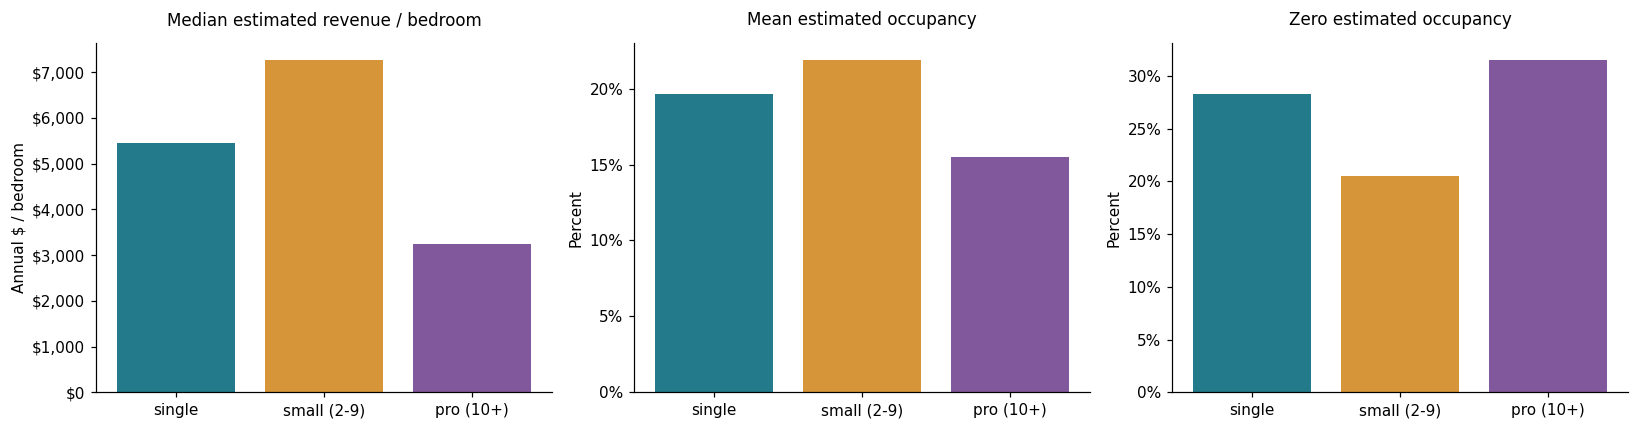

In [4]:
def summary(frame, tier='host_tier'):
    return frame.groupby(tier,observed=True).agg(
        listings=('id','size'),hosts=('host_id','nunique'),
        revenue_mean=('revenue_per_bedroom','mean'),revenue_median=('revenue_per_bedroom','median'),
        revenue_p25=('revenue_per_bedroom',lambda s:s.quantile(.25)),revenue_p75=('revenue_per_bedroom',lambda s:s.quantile(.75)),
        occupancy_pct=('occupancy_rate_l365d',lambda s:100*s.mean()),
        zero_pct=('zero_occupancy',lambda s:100*s.mean()),cap_pct=('occupancy_capped',lambda s:100*s.mean())).reindex(TIERS)
raw = summary(d)
display(raw)
host_means = d.groupby(['host_tier','host_id'],observed=True).agg(revenue=('revenue_per_bedroom','mean'),occupancy=('occupancy_rate_l365d','mean'))
display(host_means.groupby(level=0,observed=True).mean().rename(columns={'revenue':'host_weighted_revenue','occupancy':'host_weighted_occupancy'}))
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,col,title in zip(axes,['revenue_median','occupancy_pct','zero_pct'],['Median estimated revenue / bedroom','Mean estimated occupancy','Zero estimated occupancy']):
    ax.bar(TIERS,raw[col],color=COLORS); ax.set_title(title,fontsize=11)
    ax.set_ylabel('Annual $ / bedroom' if col=='revenue_median' else 'Percent')
    ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}' if col=='revenue_median' else '{x:.0f}%'))
plt.tight_layout(); plt.show()

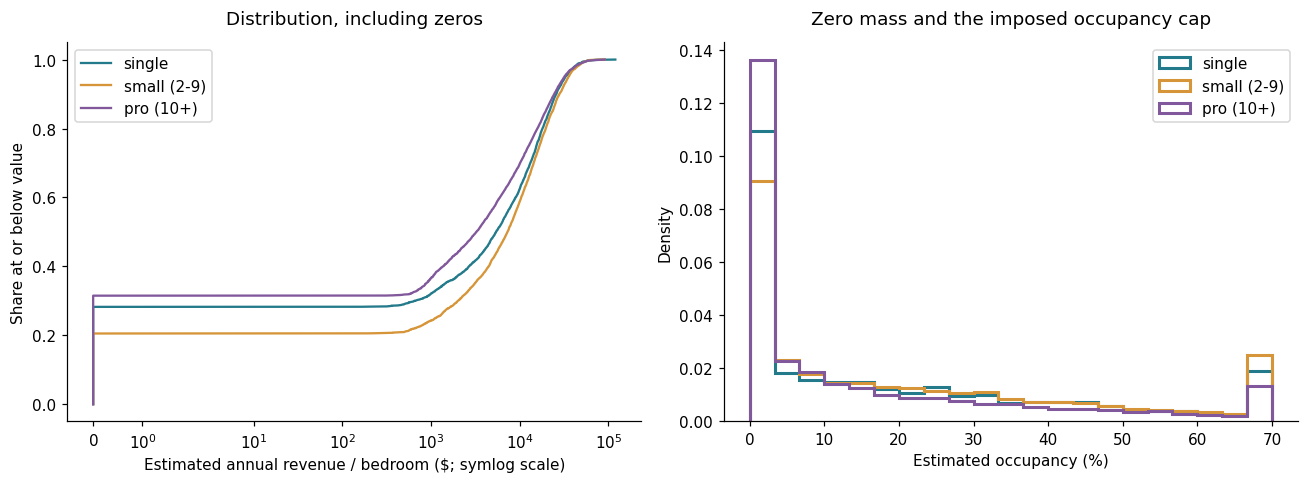

**Unadjusted result:** single-host listings have median estimated revenue per bedroom of **$5,440**, versus **$3,252** for pros. Mean estimated occupancy differs by **+4.16 percentage points**. These are composition-sensitive comparisons, not the effect of becoming independent.

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for tier,color in zip(TIERS,COLORS):
    x=d.loc[d.host_tier.eq(tier),'revenue_per_bedroom'].sort_values().to_numpy()
    axes[0].plot(x,np.arange(1,len(x)+1)/len(x),label=tier,color=color)
    o=d.loc[d.host_tier.eq(tier),'occupancy_rate_l365d']*100
    axes[1].hist(o,bins=np.linspace(0,70,22),density=True,histtype='step',lw=2,label=tier,color=color)
axes[0].set(xscale='symlog',xlabel='Estimated annual revenue / bedroom ($; symlog scale)',ylabel='Share at or below value',title='Distribution, including zeros')
axes[1].set(xlabel='Estimated occupancy (%)',ylabel='Density',title='Zero mass and the imposed occupancy cap')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
a,b=raw.loc['single'],raw.loc['pro (10+)']
display(Markdown(f"**Unadjusted result:** single-host listings have median estimated revenue per bedroom of **${a.revenue_median:,.0f}**, versus **${b.revenue_median:,.0f}** for pros. Mean estimated occupancy differs by **{a.occupancy_pct-b.occupancy_pct:+.2f} percentage points**. These are composition-sensitive comparisons, not the effect of becoming independent."))

### Do the groups sell different products?
Host size can stand in for location, property type, or amenities. The composition table is the bridge between raw gaps and adjusted comparisons. Amenities are parsed from the JSON list; keyword flags represent advertised access (a shared pool also counts), not verified quality.

host_tier,single,small (2-9),pro (10+)
bedrooms,2.025,1.918,1.717
bathrooms,1.655,1.630,1.643
accommodates,4.962,4.993,5.131
mi_to_beach_approx,3.609,2.636,1.438
mi_to_airport,7.544,7.074,6.900
mi_to_stadium,12.845,13.315,12.716
pool,0.582,0.553,0.787
hot_tub,0.156,0.169,0.278
parking,0.884,0.852,0.622
workspace,0.541,0.610,0.698


room_type,Entire home/apt,Hotel room,Private room,Shared room
host_tier,,,,
single,81.809,0.000,18.123,0.069
small (2-9),80.788,0.358,18.222,0.632
pro (10+),87.575,2.353,9.749,0.324


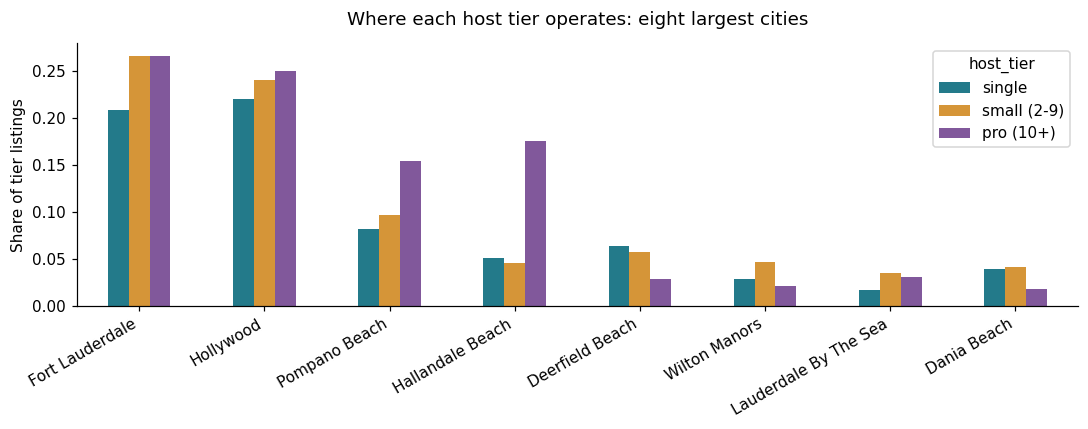

In [6]:
def features(frame):
    x=frame.copy()
    def parse(v):
        try: return json.loads(v) if isinstance(v,str) else []
        except (ValueError,TypeError): return []
    amenities=x.amenities.map(parse)
    text=amenities.map(lambda a:' | '.join(str(v).lower() for v in a))
    patterns={'pool':'pool','hot_tub':'hot tub','parking':'free.*parking|free driveway','workspace':'dedicated workspace','self_checkin':'self check-in','pets':'pets allowed','waterfront':'waterfront|beach access'}
    for name,pattern in patterns.items(): x[name]=text.str.contains(pattern,regex=True).astype(int)
    p=x.property_type.fillna('').str.lower()
    x['property_group']=np.select([p.str.contains('hotel|resort|aparthotel'),p.str.contains('condo|rental unit|apartment|loft'),p.str.contains('home|villa|townhouse|bungalow|cottage')],['Hotel/resort','Apartment/condo','House/villa'],default='Other')
    x['host_tier']=pd.Categorical(x.host_tier,categories=TIERS)
    x['occupancy_pct']=100*x.occupancy_rate_l365d
    x['log_rpb']=np.log1p(x.revenue_per_bedroom)
    x['any_activity']=(x.estimated_occupancy_l365d>0).astype(int)
    x['bedroom_band']=pd.cut(x.bedrooms,[-1,1,2,3,np.inf],labels=['Studio / 1','2','3','4+']).astype(str)
    x['beach_band']=pd.cut(x.mi_to_beach_approx,[-np.inf,1,3,np.inf],labels=['Within 1 mi','1–3 mi','3+ mi']).astype(str)
    return x
x=features(d)
NUM=['bedrooms','bathrooms','accommodates','mi_to_beach_approx','mi_to_airport','mi_to_stadium','pool','hot_tub','parking','workspace','self_checkin','pets','waterfront']
CAT=['host_tier','city','room_type','property_type']
display(x.groupby('host_tier',observed=True)[NUM].mean().T)
display(pd.crosstab(x.host_tier,x.room_type,normalize='index')*100)
fig,ax=plt.subplots(figsize=(10,4))
pd.crosstab(x.city,x.host_tier,normalize='columns').reindex(columns=TIERS).loc[x.city.value_counts().head(8).index].plot.bar(ax=ax,color=COLORS)
ax.set(title='Where each host tier operates: eight largest cities',ylabel='Share of tier listings',xlabel=''); plt.xticks(rotation=30,ha='right'); plt.tight_layout(); plt.show()

## 3. Does host size matter among comparable listings?
### A. Association models with host-clustered uncertainty
Fit three specifications for each outcome: host tier alone; tier plus location/physical characteristics; then advertised amenities. Pro is the reference group. City and broad property family (apartment/condo, house/villa, hotel/resort, other) enter as categories, rather than arbitrary numeric codes. Broad families avoid redundant controls where detailed property labels already encode room type. Standard errors cluster by host because a large portfolio's listings are not independent observations.

Revenue uses log(1 + dollars per bedroom) to reduce skew while retaining zeros. A coefficient is a **log-point difference in revenue + 1**; exponentiating it compares geometric means of revenue + 1, not arithmetic dollar earnings. Occupancy is modeled directly in percentage points. Linear models summarize conditional associations; they need not predict valid occupancy at the boundaries. Neither model identifies causality or removes unobserved quality differences.

Complete-case model sample: 15698 of 15698 | Hosts: 5641


,outcome,model,contrast,estimate,low,high,p,n,R2
0,log_rpb,Tier only,single vs pro,0.431,-0.087,0.949,0.103,15698,0.015
1,log_rpb,Tier only,small (2-9) vs pro,1.151,0.632,1.670,0.000,15698,0.015
2,log_rpb,Physical/location,single vs pro,-0.399,-0.710,-0.088,0.012,15698,0.166
3,log_rpb,Physical/location,small (2-9) vs pro,0.437,0.130,0.745,0.005,15698,0.166
4,log_rpb,With amenities,single vs pro,-0.281,-0.570,0.009,0.057,15698,0.240
5,log_rpb,With amenities,small (2-9) vs pro,0.373,0.086,0.659,0.011,15698,0.240
6,occupancy_pct,Tier only,single vs pro,4.162,1.722,6.602,0.001,15698,0.018
7,occupancy_pct,Tier only,small (2-9) vs pro,6.417,3.910,8.924,0.000,15698,0.018
8,occupancy_pct,Physical/location,single vs pro,-0.360,-2.384,1.664,0.727,15698,0.125
9,occupancy_pct,Physical/location,small (2-9) vs pro,2.547,0.523,4.571,0.014,15698,0.125


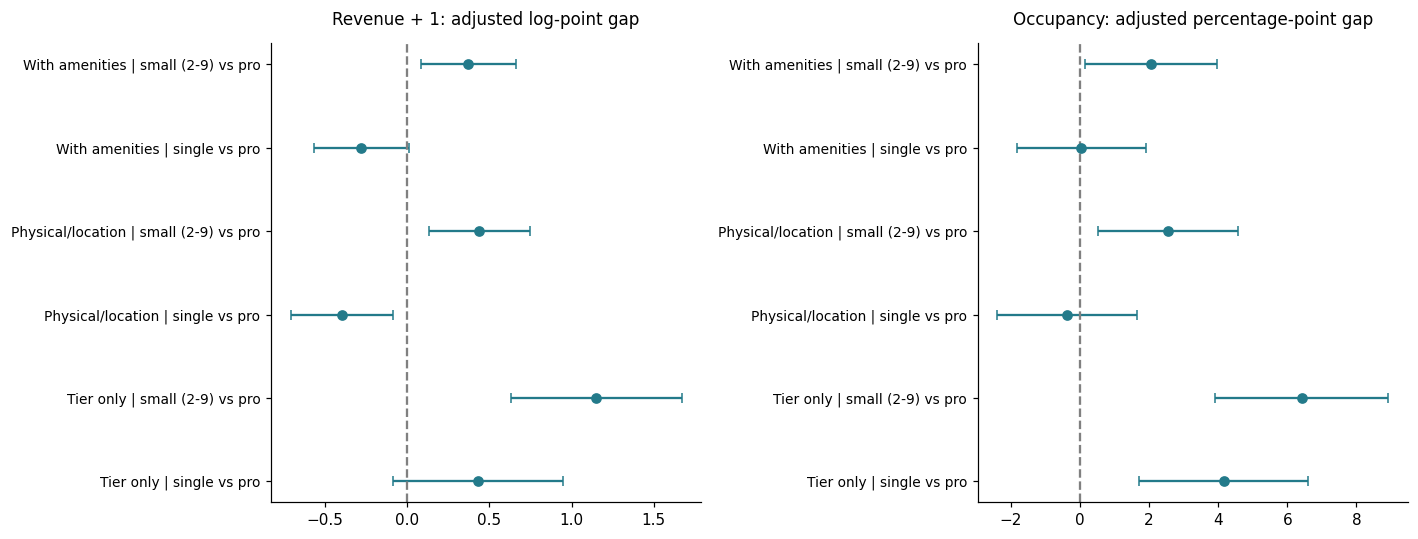

In [7]:
tier_term = "C(host_tier, Treatment(reference='pro (10+)'))"
physical = 'C(city) + C(room_type) + C(property_group) + bedrooms + bathrooms + accommodates + mi_to_beach_approx + mi_to_airport + mi_to_stadium'
amenity_terms = 'pool + hot_tub + parking + workspace + self_checkin + pets + waterfront'
rhs = {'Tier only':tier_term,'Physical/location':tier_term+' + '+physical,'With amenities':tier_term+' + '+physical+' + '+amenity_terms}
model_columns=NUM+CAT+['host_id','log_rpb','occupancy_pct']
model_data=x.dropna(subset=model_columns).copy()
print('Complete-case model sample:',len(model_data),'of',len(x),'| Hosts:',model_data.host_id.nunique())
def clustered(formula, frame, weights=None):
    fit = smf.ols(formula,frame) if weights is None else smf.wls(formula,frame,weights=weights)
    return fit.fit(cov_type='cluster',cov_kwds={'groups':frame.host_id},use_t=True)
def tier_rows(model, outcome, spec):
    ci=model.conf_int(); rows=[]
    for term in model.params.index:
        if term.startswith('C(host_tier'):
            rows.append({'outcome':outcome,'model':spec,'contrast':term.split('[T.')[-1].rstrip(']')+' vs pro',
                         'estimate':model.params[term],'low':ci.loc[term,0],'high':ci.loc[term,1],'p':model.pvalues[term], 'n':int(model.nobs),'R2':model.rsquared})
    return rows
fits={}; coef_rows=[]
for outcome in ['log_rpb','occupancy_pct']:
    for name,formula in rhs.items():
        fit=clustered(outcome+' ~ '+formula,model_data); fits[outcome,name]=fit
        coef_rows.extend(tier_rows(fit,outcome,name))
coef=pd.DataFrame(coef_rows)
display(coef)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,outcome,title in zip(axes,['log_rpb','occupancy_pct'],['Revenue + 1: adjusted log-point gap','Occupancy: adjusted percentage-point gap']):
    t=coef[coef.outcome.eq(outcome)].reset_index(drop=True)
    ax.errorbar(t.estimate,np.arange(len(t)),xerr=[t.estimate-t.low,t.high-t.estimate],fmt='o',color=COLORS[0],capsize=3)
    ax.set_yticks(np.arange(len(t)),t.model+' | '+t.contrast,fontsize=9); ax.axvline(0,color='gray',ls='--'); ax.set_title(title,fontsize=11)
plt.tight_layout(); plt.show()

In [8]:
for outcome,unit in [('log_rpb','log points'),('occupancy_pct','percentage points')]:
    r=coef[(coef.outcome==outcome)&(coef.model=='With amenities')&(coef.contrast=='single vs pro')].iloc[0]
    display(Markdown(f"**Adjusted single vs pro ({outcome}): {r.estimate:+.3f} {unit}**, 95% CI [{r.low:+.3f}, {r.high:+.3f}], p={r.p:.3g}. This holds the included listing traits constant; omitted quality, pricing strategy, and host selection remain possible explanations."))
# Common-profile fitted values are summaries, not causal counterfactuals.
standardized=[]
for tier in TIERS:
    z=model_data.copy(); z['host_tier']=pd.Categorical([tier]*len(z),categories=TIERS)
    standardized.append({'tier':tier,'mean_fitted_occupancy_pct':fits['occupancy_pct','With amenities'].predict(z).mean(),
                         'mean_fitted_log_revenue_plus_1':fits['log_rpb','With amenities'].predict(z).mean()})
display(pd.DataFrame(standardized))

**Adjusted single vs pro (log_rpb): -0.281 log points**, 95% CI [-0.570, +0.009], p=0.0573. This holds the included listing traits constant; omitted quality, pricing strategy, and host selection remain possible explanations.

**Adjusted single vs pro (occupancy_pct): +0.047 percentage points**, 95% CI [-1.823, +1.917], p=0.961. This holds the included listing traits constant; omitted quality, pricing strategy, and host selection remain possible explanations.

,tier,mean_fitted_occupancy_pct,mean_fitted_log_revenue_plus_1
0,single,17.603,6.147
1,small (2-9),19.621,6.800
2,pro (10+),17.556,6.428


### What the adjusted comparison shows
The roughly **4.16-point raw single-host occupancy advantage falls to 0.05 points** after adjustment (95% CI −1.82 to +1.92). Thus the data do not establish a general single-host occupancy advantage among otherwise similar measured listings. Small hosts retain an estimated **2.07-point** advantage over pros (CI 0.15 to 3.98). The single-host revenue coefficient is negative but its interval includes zero; the small-host coefficient is positive. This is stronger evidence for distinguishing small operators from both singles and pros than for combining them into one independent group.

### B. Is the difference about being active or filling more nights?
The mass at zero warrants two separate questions. A host-clustered binomial model estimates the association with **any review-derived activity**. An occupancy regression among positive estimates describes intensity conditional on activity. This restriction selects successful/reviewed listings, so it must not replace the all-listing result. Odds ratios are not percentage-point changes.

In [9]:
activity=smf.glm('any_activity ~ '+rhs['With amenities'],model_data,family=sm.families.Binomial()).fit(cov_type='cluster',cov_kwds={'groups':model_data.host_id})
terms=[t for t in activity.params.index if t.startswith('C(host_tier')]
aci=activity.conf_int().loc[terms]
display(pd.DataFrame({'odds_ratio':np.exp(activity.params[terms]),'low':np.exp(aci[0]),'high':np.exp(aci[1]),'p':activity.pvalues[terms]}))
positive=model_data[model_data.any_activity.eq(1)]
intensity=clustered('occupancy_pct ~ '+rhs['With amenities'],positive)
display(pd.DataFrame(tier_rows(intensity,'occupancy_pct | positive','Conditional intensity')))
print('Positive-activity sample:',len(positive),'| Hosts:',positive.host_id.nunique())

Positive-activity sample: 11367 | Hosts: 4413


,odds_ratio,low,high,p
"C(host_tier, Treatment(reference='pro (10+)'))[T.single]",0.730,0.603,0.883,0.001
"C(host_tier, Treatment(reference='pro (10+)'))[T.small (2-9)]",1.188,0.977,1.444,0.084


,outcome,model,contrast,estimate,low,high,p,n,R2
0,occupancy_pct | positive,Conditional intensity,single vs pro,1.368,-0.722,3.458,0.199,11367,0.126
1,occupancy_pct | positive,Conditional intensity,small (2-9) vs pro,1.737,-0.368,3.843,0.106,11367,0.126


**Activity versus intensity.** With controls, single-host listings have lower odds of any review-derived activity than pros (odds ratio about 0.73). Among positive-activity listings, singles have about 1.37 more occupancy points, but the interval crosses zero. This explains why favorable raw comparisons should not be read as a universal independent-host advantage. The active-only sample answers a narrower question and excludes the risk of having no observed activity.

### C. Which measured characteristics are associated with performance?
Coefficients below hold the other included traits constant. Binary amenity coefficients compare advertised presence vs absence; continuous coefficients are per unit (one bedroom, one mile, or one guest). They are not a ranking of causal interventions. Pool and waterfront can proxy for building class and neighborhood quality; small revenue-per-bedroom properties also benefit mechanically from a smaller denominator.

OLS occupancy fitted values outside [0, 255/365*100]: 0.026309083959740093


,outcome,feature,estimate,low,high,p
0,log_rpb,bedrooms,0.235,0.035,0.436,0.021
1,log_rpb,bathrooms,-0.134,-0.288,0.020,0.087
2,log_rpb,accommodates,-0.153,-0.239,-0.067,0.000
3,log_rpb,mi_to_beach_approx,-0.068,-0.156,0.020,0.132
4,log_rpb,mi_to_airport,0.061,-0.058,0.179,0.315
5,log_rpb,mi_to_stadium,0.005,-0.119,0.129,0.936
6,log_rpb,pool,-0.395,-0.614,-0.175,0.000
7,log_rpb,hot_tub,-1.092,-1.463,-0.720,0.000
8,log_rpb,parking,0.460,0.076,0.843,0.019
9,log_rpb,workspace,0.320,0.106,0.534,0.003


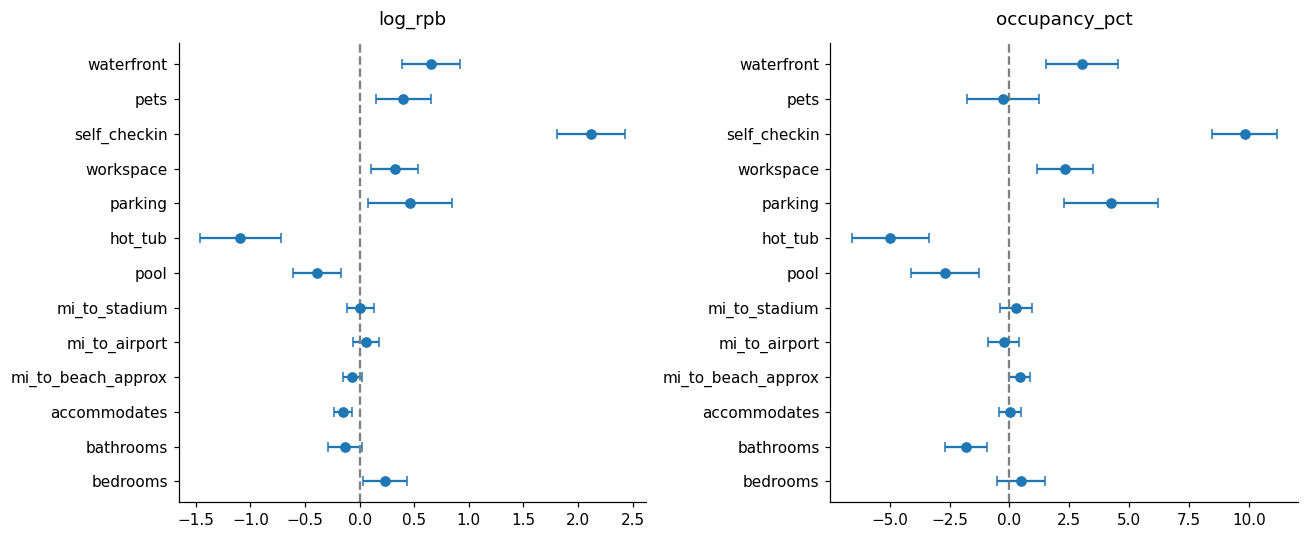

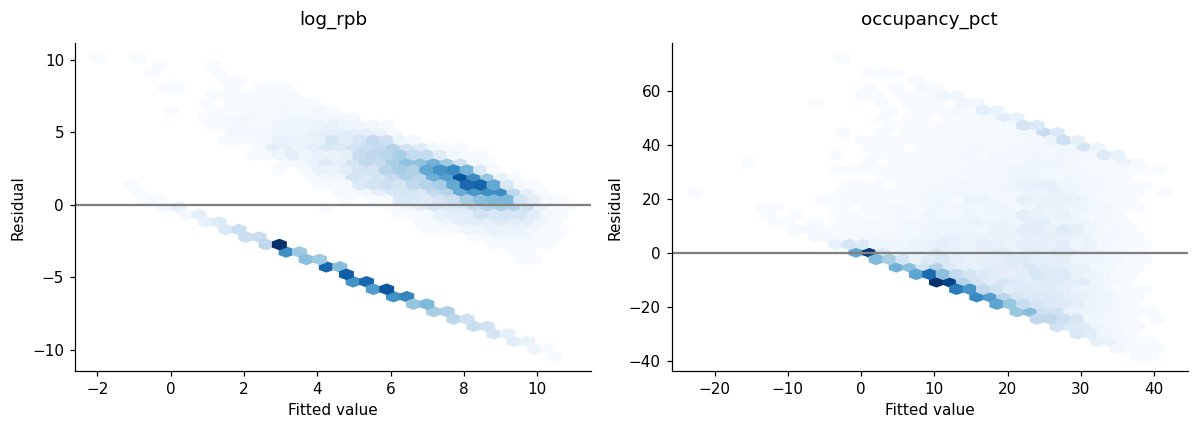

In [10]:
drivers=[]
for outcome in ['log_rpb','occupancy_pct']:
    m=fits[outcome,'With amenities']; ci=m.conf_int()
    for term in NUM:
        drivers.append({'outcome':outcome,'feature':term,'estimate':m.params[term],'low':ci.loc[term,0],'high':ci.loc[term,1],'p':m.pvalues[term]})
drivers=pd.DataFrame(drivers)
display(drivers)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,outcome in zip(axes,['log_rpb','occupancy_pct']):
    t=drivers[drivers.outcome.eq(outcome)]
    ax.errorbar(t.estimate,np.arange(len(t)),xerr=[t.estimate-t.low,t.high-t.estimate],fmt='o',capsize=3)
    ax.set_yticks(np.arange(len(t)),t.feature); ax.axvline(0,color='gray',ls='--'); ax.set_title(outcome)
plt.tight_layout(); plt.show()
# Inspect boundary fit and residual structure rather than assume OLS is calibrated.
pred=fits['occupancy_pct','With amenities'].fittedvalues
print('OLS occupancy fitted values outside [0, 255/365*100]:',((pred<0)|(pred>255/365*100)).mean())
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,outcome in zip(axes,['log_rpb','occupancy_pct']):
    m=fits[outcome,'With amenities']
    ax.hexbin(m.fittedvalues,m.resid,gridsize=35,mincnt=1,cmap='Blues'); ax.axhline(0,color='gray'); ax.set(xlabel='Fitted value',ylabel='Residual',title=outcome)
plt.tight_layout(); plt.show()

### D. Ratings and Superhost: useful signals, weaker driver claims
Ratings are never filled with a mean or a zero: their missingness reveals the absence of reviews. Restrict this secondary model to listings with an observed overall rating. Add Superhost and overall rating to the same physical controls; report the sample size and keep the main result separate. Both reputation measures can be consequences of prior performance, and ratings may reflect the same year's guests.

In [11]:
rated=model_data.dropna(subset=['review_scores_rating','host_is_superhost']).copy()
rep_rows=[]
for outcome in ['log_rpb','occupancy_pct']:
    m=clustered(outcome+' ~ '+rhs['With amenities']+' + review_scores_rating + host_is_superhost',rated)
    ci=m.conf_int()
    for term in ['review_scores_rating','host_is_superhost']:
        rep_rows.append({'outcome':outcome,'signal':term,'estimate':m.params[term],'low':ci.loc[term,0],'high':ci.loc[term,1],'n':int(m.nobs)})
display(pd.DataFrame(rep_rows))
display(rated.groupby('host_tier',observed=True)[['review_scores_rating','review_scores_cleanliness','review_scores_communication','host_is_superhost']].mean())

,outcome,signal,estimate,low,high,n
0,log_rpb,review_scores_rating,0.634,0.415,0.852,12822
1,log_rpb,host_is_superhost,1.309,1.115,1.504,12822
2,occupancy_pct,review_scores_rating,3.361,2.559,4.163,12822
3,occupancy_pct,host_is_superhost,11.452,9.591,13.312,12822


,review_scores_rating,review_scores_cleanliness,review_scores_communication,host_is_superhost
host_tier,,,,
single,4.796,4.791,4.870,0.416
small (2-9),4.789,4.781,4.863,0.533
pro (10+),4.657,4.660,4.766,0.399


## 4. What predicts performance for previously unseen hosts?
### Validation design
One 25% holdout split is made **by host**, shared across outcomes. No host appears in training and testing. Within training, three-fold grouped cross-validation compares a mean baseline, ridge regression, a shallow tree, and a random forest. All imputation, scaling, and one-hot encoding are fit inside each fold. Candidate settings are fixed in advance; select by training CV MAE, then evaluate once on holdout.

Predict log(1 + revenue/bedroom) and occupancy percentage points separately. Revenue model scores stay in log units; we do not exponentiate them and call the result expected dollar revenue. MAE and R² are compared with a baseline. Weak performance means the measured features leave much unexplained, even when coefficients are statistically precise. This is cross-sectional generalization to unseen accounts, not a future-year forecast.

In [12]:
X=x[NUM+CAT].copy()
for c in CAT: X[c]=X[c].astype(str)
FORBIDDEN={'price','minimum_nights','number_of_reviews','number_of_reviews_ltm','availability_365','zero_occupancy','occupancy_capped','review_scores_rating','host_is_superhost','revenue_per_bedroom','occupancy_rate_l365d'}
assert not (set(X.columns)&FORBIDDEN)
train,test=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED).split(X,groups=x.host_id))
assert not set(x.iloc[train].host_id)&set(x.iloc[test].host_id)
print('Train/test listings:',len(train),len(test),'| Hosts:',x.iloc[train].host_id.nunique(),x.iloc[test].host_id.nunique())
display(pd.crosstab(pd.Series(np.where(np.isin(np.arange(len(x)),test),'test','train'),index=x.index),x.host_tier,normalize='index'))
def pipeline(estimator, columns=None):
    columns=list(X.columns) if columns is None else columns
    num=[c for c in NUM if c in columns]; cat=[c for c in CAT if c in columns]
    prep=ColumnTransformer([('num',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
                            ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])
    return Pipeline([('prep',prep),('model',estimator)])
def candidates():
    return {'Mean baseline':DummyRegressor(), 'Ridge':Ridge(alpha=10),
            'Shallow tree':DecisionTreeRegressor(max_depth=4,min_samples_leaf=100,random_state=SEED),
            'Random forest':RandomForestRegressor(n_estimators=140,max_depth=12,min_samples_leaf=25,max_features=.8,n_jobs=2,random_state=SEED)}
cv=GroupKFold(n_splits=3)
cv_rows=[]; best={}; test_predictions={}; test_rows=[]
for outcome in ['log_rpb','occupancy_pct']:
    y=x[outcome]; results=[]
    for name,est in candidates().items():
        p=pipeline(est)
        scores=-cross_val_score(p,X.iloc[train],y.iloc[train],groups=x.iloc[train].host_id,cv=cv,scoring='neg_mean_absolute_error',n_jobs=1)
        row={'outcome':outcome,'model':name,'cv_mae':scores.mean(),'cv_sd':scores.std()}; cv_rows.append(row); results.append(row)
    chosen=min(results,key=lambda r:r['cv_mae'])['model']
    p=pipeline(candidates()[chosen]).fit(X.iloc[train],y.iloc[train]); best[outcome]=p
    pred=p.predict(X.iloc[test]); test_predictions[outcome]=pred
    base=np.repeat(y.iloc[train].mean(),len(test))
    test_rows.append({'outcome':outcome,'chosen':chosen,'test_mae':mean_absolute_error(y.iloc[test],pred),'test_R2':r2_score(y.iloc[test],pred),'baseline_mae':mean_absolute_error(y.iloc[test],base)})
cv_results=pd.DataFrame(cv_rows); test_results=pd.DataFrame(test_rows)
display(cv_results); display(test_results)

Train/test listings: 11527 4171 | Hosts: 4230 1411


host_tier,single,small (2-9),pro (10+)
row_0,,,
test,0.175,0.290,0.535
train,0.190,0.307,0.503


,outcome,model,cv_mae,cv_sd
0,log_rpb,Mean baseline,3.604,0.019
1,log_rpb,Ridge,2.922,0.020
2,log_rpb,Shallow tree,2.979,0.040
3,log_rpb,Random forest,2.747,0.054
4,occupancy_pct,Mean baseline,17.843,0.168
5,occupancy_pct,Ridge,15.439,0.346
6,occupancy_pct,Shallow tree,15.833,0.415
7,occupancy_pct,Random forest,15.117,0.286


,outcome,chosen,test_mae,test_R2,baseline_mae
0,log_rpb,Random forest,2.834,0.233,3.509
1,occupancy_pct,Random forest,13.539,0.238,17.102


### What does the selected model rely on?
Permutation importance shuffles each original feature in the holdout and measures the increase in MAE, averaged across eight shuffles. It keeps all one-hot columns for a categorical field together. Correlated variables can substitute for one another, so low importance is not proof that a trait is irrelevant. The spread across shuffles is **not** a confidence interval over hosts.

log_rpb
occupancy_pct


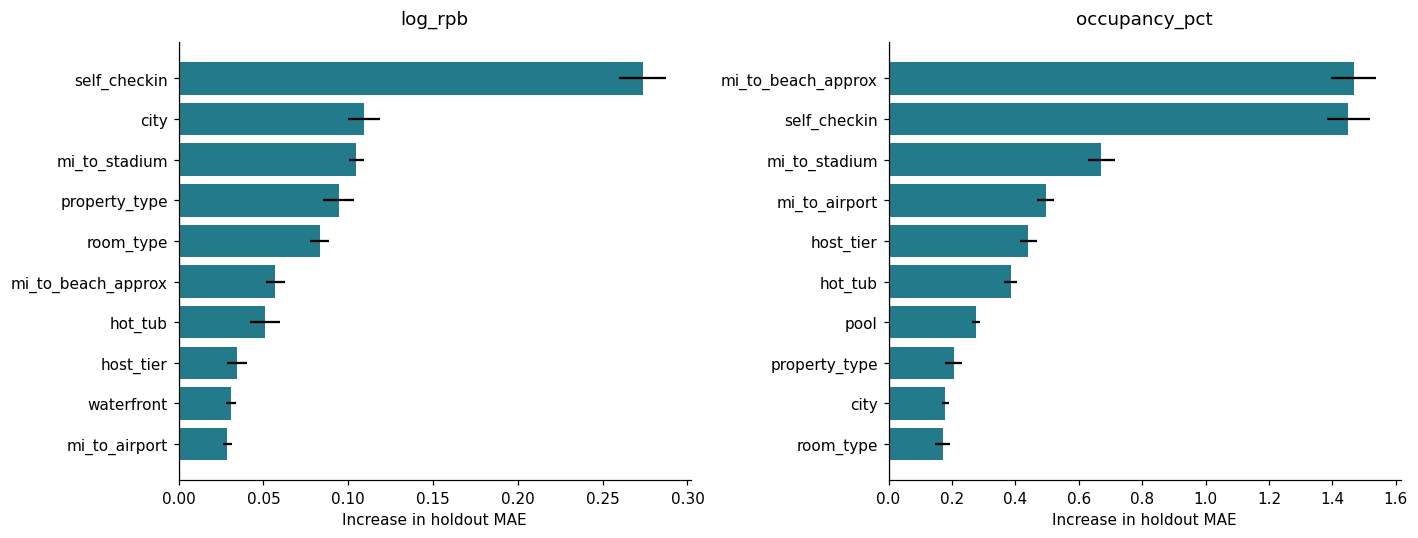

,feature,increase_MAE,shuffle_sd
10,self_checkin,0.274,0.014
14,city,0.109,0.009
5,mi_to_stadium,0.105,0.005
16,property_type,0.094,0.009
15,room_type,0.083,0.006
3,mi_to_beach_approx,0.057,0.005
7,hot_tub,0.051,0.009
13,host_tier,0.034,0.006
12,waterfront,0.031,0.003
4,mi_to_airport,0.029,0.002


,feature,increase_MAE,shuffle_sd
3,mi_to_beach_approx,1.467,0.071
10,self_checkin,1.450,0.068
5,mi_to_stadium,0.671,0.043
4,mi_to_airport,0.495,0.028
13,host_tier,0.441,0.027
7,hot_tub,0.386,0.021
6,pool,0.275,0.013
16,property_type,0.205,0.026
14,city,0.179,0.010
15,room_type,0.171,0.024


,outcome,MAE_with_tier,MAE_without_tier,improvement_from_tier
0,log_rpb,2.834,2.852,0.018
1,occupancy_pct,13.539,13.602,0.063


In [13]:
importances={}
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,outcome in zip(axes,['log_rpb','occupancy_pct']):
    p=best[outcome]
    imp=permutation_importance(p,X.iloc[test],x[outcome].iloc[test],scoring='neg_mean_absolute_error',n_repeats=8,random_state=SEED,n_jobs=1)
    t=pd.DataFrame({'feature':X.columns,'increase_MAE':imp.importances_mean,'shuffle_sd':imp.importances_std}).sort_values('increase_MAE',ascending=False)
    importances[outcome]=t
    top=t.head(10).iloc[::-1]
    ax.barh(top.feature,top.increase_MAE,xerr=top.shuffle_sd,color=COLORS[0]); ax.axvline(0,color='gray'); ax.set(title=outcome,xlabel='Increase in holdout MAE')
plt.tight_layout(); plt.show()
for outcome,t in importances.items():
    print(outcome); display(t)
# Same fixed model class, with and without host tier; holdout is not used to retune.
ablation=[]
for outcome in best:
    chosen=test_results.set_index('outcome').loc[outcome,'chosen']
    cols=[c for c in X.columns if c!='host_tier']
    p=pipeline(candidates()[chosen],cols).fit(X.iloc[train][cols],x[outcome].iloc[train])
    without=mean_absolute_error(x[outcome].iloc[test],p.predict(X.iloc[test][cols]))
    with_tier=mean_absolute_error(x[outcome].iloc[test],test_predictions[outcome])
    ablation.append({'outcome':outcome,'MAE_with_tier':with_tier,'MAE_without_tier':without,'improvement_from_tier':without-with_tier})
display(pd.DataFrame(ablation))

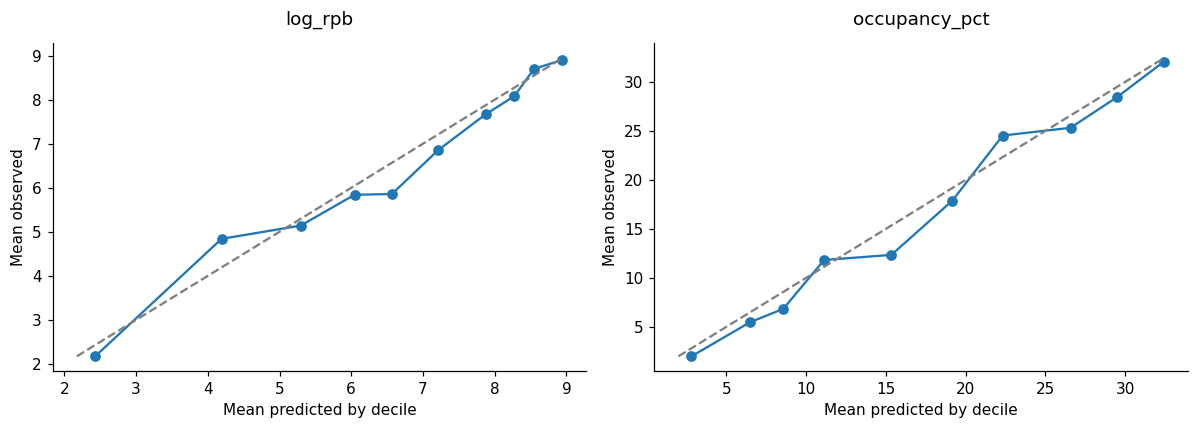

,outcome,tier,n_test,MAE,mean_error_pred_minus_actual
0,log_rpb,pro (10+),2232,2.855,0.239
1,log_rpb,single,728,2.928,0.008
2,log_rpb,small (2-9),1211,2.740,0.010
3,occupancy_pct,pro (10+),2232,11.025,1.313
4,occupancy_pct,single,728,15.940,0.503
5,occupancy_pct,small (2-9),1211,16.730,-0.100


In [14]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
errors=[]
for ax,outcome in zip(axes,['log_rpb','occupancy_pct']):
    t=pd.DataFrame({'pred':test_predictions[outcome],'actual':x[outcome].iloc[test].to_numpy(),'tier':x.host_tier.iloc[test].astype(str).to_numpy()})
    t['bin']=pd.qcut(t.pred,10,duplicates='drop')
    cal=t.groupby('bin',observed=True)[['pred','actual']].mean()
    ax.plot(cal.pred,cal.actual,'o-'); lo=min(cal.min()); hi=max(cal.max()); ax.plot([lo,hi],[lo,hi],'--',color='gray')
    ax.set(title=outcome,xlabel='Mean predicted by decile',ylabel='Mean observed')
    for tier,g in t.groupby('tier'):
        errors.append({'outcome':outcome,'tier':tier,'n_test':len(g),'MAE':mean_absolute_error(g.actual,g.pred),'mean_error_pred_minus_actual':(g.pred-g.actual).mean()})
plt.tight_layout(); plt.show(); display(pd.DataFrame(errors))

### What the prediction exercise adds
The random forest has the lowest training cross-validation MAE for both outcomes. On unseen hosts it explains about **23–24% of outcome variance**; occupancy MAE is **13.54 percentage points**, versus 17.10 for the mean baseline. Predictions therefore provide broad benchmarks, not precise earnings forecasts.

Self check-in is the strongest revenue-model signal; beach distance and self check-in lead occupancy importance. These can proxy for property class, listing completeness, and management practices. Host tier adds only **0.018 log units** and **0.063 occupancy points** of holdout MAE improvement when the model is refit without it. That is modest incremental predictive value, despite meaningful raw tier differences.

### A small tree for readable patterns
A depth-three occupancy tree is an explanatory aid, not a replacement for the selected model. It excludes host tier and location categories to keep the rules readable. Leaf averages are training estimates; its holdout score shows whether these simple rules travel to other hosts. Do not interpret a split threshold as an optimal investment or pricing cutoff.

Readable tree test MAE: 14.315131306864672


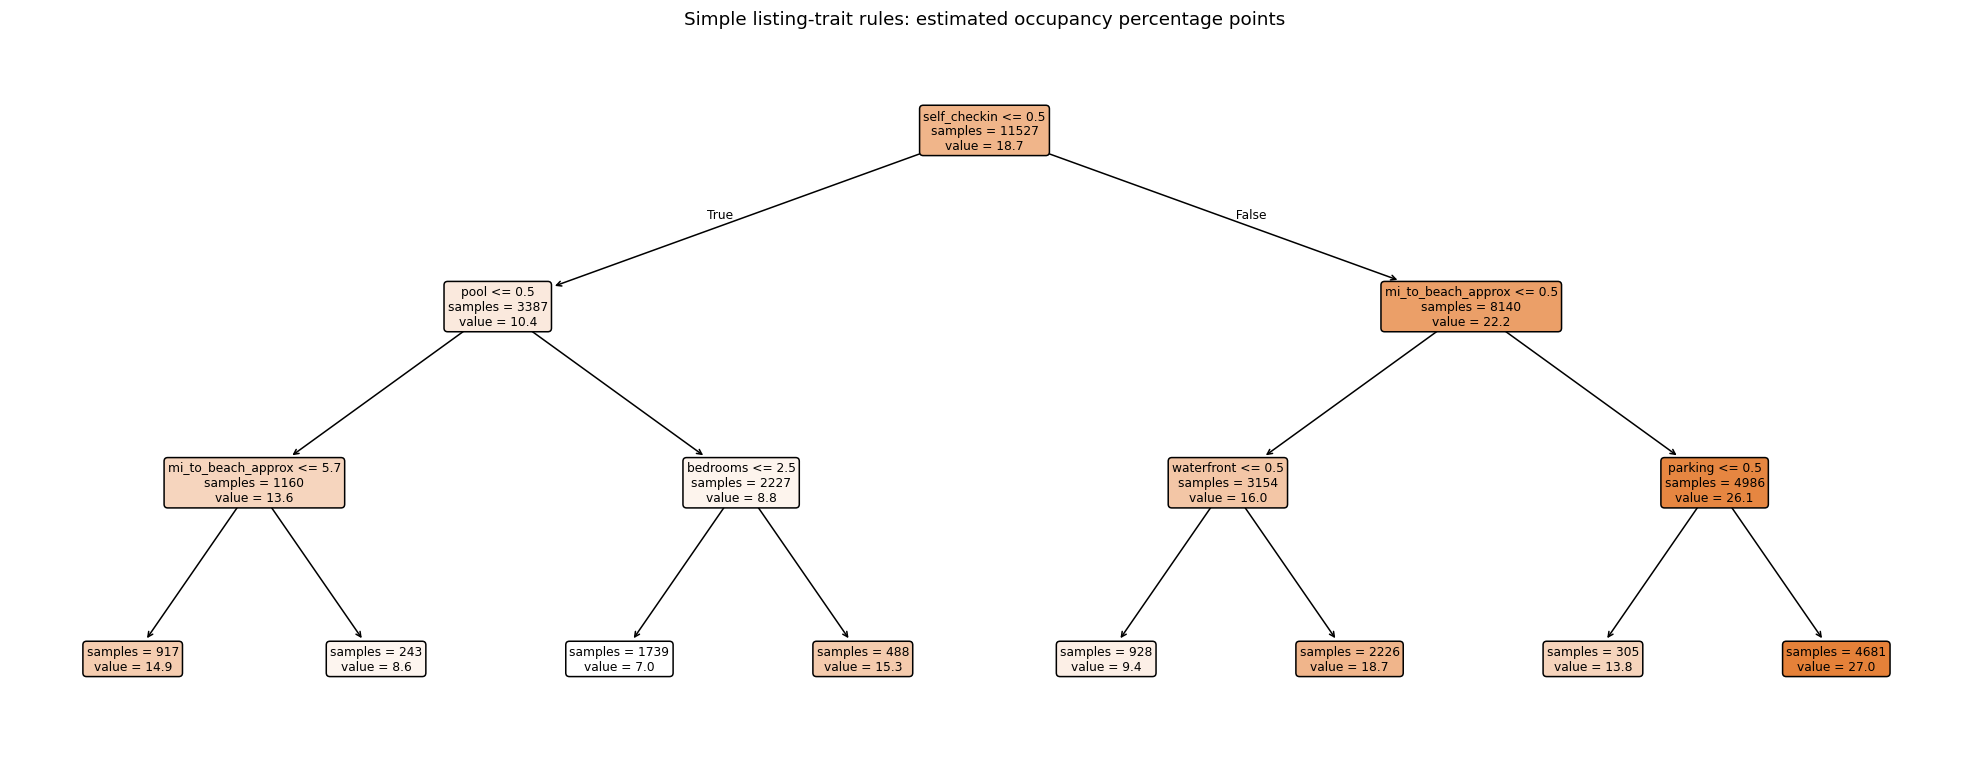

In [15]:
tree_features=['bedrooms','bathrooms','accommodates','mi_to_beach_approx','pool','parking','self_checkin','waterfront']
fill=SimpleImputer(strategy='median').fit(X.iloc[train][tree_features])
tree=DecisionTreeRegressor(max_depth=3,min_samples_leaf=200,random_state=SEED).fit(fill.transform(X.iloc[train][tree_features]),x.occupancy_pct.iloc[train])
print('Readable tree test MAE:',mean_absolute_error(x.occupancy_pct.iloc[test],tree.predict(fill.transform(X.iloc[test][tree_features]))))
fig,ax=plt.subplots(figsize=(18,7))
plot_tree(tree,feature_names=tree_features,filled=True,rounded=True,impurity=False,precision=1,fontsize=8,ax=ax)
ax.set_title('Simple listing-trait rules: estimated occupancy percentage points'); plt.tight_layout(); plt.show()

## 5. Where do independents beat pros?
### A. Like-for-like strata with observed overlap
Compare single vs pro listings within **city × room type × bedroom band × beach-distance band**. Require at least 10 listings and five distinct hosts in each group. Weight each qualifying stratum by the smaller of its single/pro listing counts. This targets the overlapping market rather than extrapolating to products sold by only one tier. It controls broad product mix but not condition, decor, management quality, or exact location.

Report both arithmetic dollars per bedroom and occupancy points. A positive gap favors single hosts. Coverage and unmatched listings matter as much as the gap; these are descriptive standardized comparisons, not a causal matching estimate.

In [16]:
pair=x[x.host_tier.isin(['single','pro (10+)'])].copy()
keys=['city','room_type','bedroom_band','beach_band']
g=pair.groupby(keys+['host_tier'],observed=True).agg(n=('id','size'),hosts=('host_id','nunique'),rev=('revenue_per_bedroom','mean'),occ=('occupancy_pct','mean')).unstack('host_tier')
keep=(g['n']['single']>=10)&(g['n']['pro (10+)']>=10)&(g['hosts']['single']>=5)&(g['hosts']['pro (10+)']>=5)
common=g.loc[keep].copy()
w=np.minimum(common['n']['single'],common['n']['pro (10+)'])
common_results=pd.DataFrame({'metric':['Annual dollars per bedroom','Occupancy percentage points'],
    'single_minus_pro':[np.average(common[v]['single']-common[v]['pro (10+)'],weights=w) for v in ['rev','occ']]})
display(common_results)
print('Qualifying strata:',len(common),'of',len(g))
print('Listings retained:',int(common['n'].sum().sum()),'of',len(pair))
print('Coverage by tier:'); display(common['n'].sum()/pair.host_tier.value_counts().reindex(['single','pro (10+)']))
common_table=pd.DataFrame({'single_n':common['n']['single'],'pro_n':common['n']['pro (10+)'],
    'revenue_gap':common['rev']['single']-common['rev']['pro (10+)'],
    'occupancy_gap_pp':common['occ']['single']-common['occ']['pro (10+)']})
display(common_table.sort_values('occupancy_gap_pp',ascending=False).head(15))

Qualifying strata: 56 of 280
Listings retained: 8343 of 10951
Coverage by tier:


,metric,single_minus_pro
0,Annual dollars per bedroom,675.677
1,Occupancy percentage points,-0.401


host_tier
single      0.602
pro (10+)   0.820
dtype: float64

single_n   pro_n  \
city             room_type       bedroom_band beach_band                      
Fort Lauderdale  Entire home/apt 4+           1–3 mi         39.000 127.000   
Hollywood        Entire home/apt 4+           Within 1 mi    11.000  66.000   
Deerfield Beach  Entire home/apt Studio / 1   Within 1 mi    22.000  96.000   
Fort Lauderdale  Entire home/apt 4+           Within 1 mi    39.000 115.000   
Hallandale Beach Entire home/apt 2            Within 1 mi    34.000 428.000   
                                 Studio / 1   Within 1 mi    24.000 784.000   
Hollywood        Entire home/apt 3            Within 1 mi    24.000 123.000   
                                 2            Within 1 mi   112.000 605.000   
Pompano Beach    Entire home/apt 4+           Within 1 mi    15.000  42.000   
Hallandale Beach Entire home/apt 3            1–3 mi         21.000  19.000   
Plantation       Entire home/apt 4+           3+ mi          10.000  27.000   
Fort Lauderdale  Entire home/apt 4+           3+ mi          27.000  34.000   
Pompano Beach    Private room    Studio / 1   Within 1 mi    10.000 114.000   
Hallandale Beach Entire home/apt 3            Within 1 mi    17.000  68.000   
Hollywood        Entire home/apt Studio / 1   3+ mi          37.000  21.000   

                                                           revenue_gap  \
city             room_type       bedroom_band beach_band                 
Fort Lauderdale  Entire home/apt 4+           1–3 mi         7,824.659   
Hollywood        Entire home/apt 4+           Within 1 mi    5,906.255   
Deerfield Beach  Entire home/apt Studio / 1   Within 1 mi    4,972.480   
Fort Lauderdale  Entire home/apt 4+           Within 1 mi    7,616.596   
Hallandale Beach Entire home/apt 2            Within 1 mi    5,385.034   
                                 Studio / 1   Within 1 mi    7,013.281   
Hollywood        Entire home/apt 3            Within 1 mi    4,595.604   
                                 2            Within 1 mi    3,422.743   
Pompano Beach    Entire home/apt 4+           Within 1 mi    5,602.628   
Hallandale Beach Entire home/apt 3            1–3 mi         3,423.217   
Plantation       Entire home/apt 4+           3+ mi          1,987.511   
Fort Lauderdale  Entire home/apt 4+           3+ mi          4,851.160   
Pompano Beach    Private room    Studio / 1   Within 1 mi    2,753.965   
Hallandale Beach Entire home/apt 3            Within 1 mi    2,136.054   
Hollywood        Entire home/apt Studio / 1   3+ mi           -536.628   

                                                           occupancy_gap_pp  
city             room_type       bedroom_band beach_band                     
Fort Lauderdale  Entire home/apt 4+           1–3 mi                 12.843  
Hollywood        Entire home/apt 4+           Within 1 mi            11.889  
Deerfield Beach  Entire home/apt Studio / 1   Within 1 mi            11.507  
Fort Lauderdale  Entire home/apt 4+           Within 1 mi            10.057  
Hallandale Beach Entire home/apt 2            Within 1 mi             9.861  
                                 Studio / 1   Within 1 mi             8.211  
Hollywood        Entire home/apt 3            Within 1 mi             8.190  
                                 2            Within 1 mi             8.043  
Pompano Beach    Entire home/apt 4+           Within 1 mi             7.199  
Hallandale Beach Entire home/apt 3            1–3 mi                  6.888  
Plantation       Entire home/apt 4+           3+ mi                   6.478  
Fort Lauderdale  Entire home/apt 4+           3+ mi                   5.762  
Pompano Beach    Private room    Studio / 1   Within 1 mi             5.158  
Hallandale Beach Entire home/apt 3            Within 1 mi             4.682  
Hollywood        Entire home/apt Studio / 1   3+ mi                   4.593

**Like-for-like result.** The 56 eligible strata cover 8,343 of 10,951 single/pro listings: about 60% of singles and 82% of pros. On this overlap population, singles average about **$676 more annual revenue per bedroom**, but **0.40 fewer occupancy points**. These are point estimates without intervals, so they do not establish an advantage. Their contrast with the broad raw ranking underscores the importance of product mix. The dollar comparison also differs from the regression's log outcome, which gives less influence to large revenues.

### B. Predefined segments, host bootstrap, and multiple comparisons
Scan cities, room types, bedroom bands, and beach-distance bands separately. Require ≥30 listings and ≥15 distinct hosts **in both** single and pro groups. Bootstrap whole hosts within each tier (1,000 repetitions), retaining every listing belonging to each sampled host. This preserves portfolio clustering and estimates a listing-weighted mean gap.

The table shows raw segment gaps and percentile 95% bootstrap intervals. Benjamini–Hochberg adjustment is applied across all eligible segment × outcome tests using centered bootstrap p-values. A segment is flagged only when **both** revenue and occupancy gaps have positive intervals and q < .05. This is an exploratory shortlist: overlapping segments and unmeasured composition still matter, and a flagged segment is not proof of a causal independent-host advantage.

In [17]:
rng=np.random.default_rng(SEED)
def bootstrap_gap(z, outcome, B=1000):
    estimates=[]; draws=[]
    for tier in ['single','pro (10+)']:
        a=z.loc[z.host_tier.eq(tier)].groupby('host_id')[outcome].agg(['sum','count'])
        estimates.append(a['sum'].sum()/a['count'].sum())
        idx=rng.integers(0,len(a),size=(B,len(a)))
        draws.append(a['sum'].to_numpy()[idx].sum(axis=1)/a['count'].to_numpy()[idx].sum(axis=1))
    observed=estimates[0]-estimates[1]; boot=draws[0]-draws[1]
    lo,hi=np.quantile(boot,[.025,.975])
    p=(1+np.sum(np.abs(boot-observed)>=abs(observed)))/(B+1)
    return observed,lo,hi,p
segment_rows=[]
for dimension in ['city','room_type','bedroom_band','beach_band']:
    for segment,z in pair.groupby(dimension,observed=True):
        counts=z.groupby('host_tier',observed=True).agg(n=('id','size'),hosts=('host_id','nunique')).reindex(['single','pro (10+)']).fillna(0)
        if counts.n.min()<30 or counts.hosts.min()<15: continue
        for outcome in ['revenue_per_bedroom','occupancy_pct']:
            gap,lo,hi,p=bootstrap_gap(z,outcome)
            segment_rows.append({'dimension':dimension,'segment':segment,'outcome':outcome,'gap':gap,'low':lo,'high':hi,'p':p,
                'single_n':int(counts.loc['single','n']),'pro_n':int(counts.loc['pro (10+)','n']),
                'single_hosts':int(counts.loc['single','hosts']),'pro_hosts':int(counts.loc['pro (10+)','hosts'])})
segments=pd.DataFrame(segment_rows)
segments['q']=multipletests(segments.p,method='fdr_bh')[1]
segments['positive_supported']=(segments.low>0)&(segments.q<.05)
both=segments.groupby(['dimension','segment']).positive_supported.agg(['all','size'])
flags=both[(both['all'])&(both['size']==2)].index
segments['both_outcomes_supported']=[(a,b) in flags for a,b in zip(segments.dimension,segments.segment)]
display(segments.sort_values(['both_outcomes_supported','dimension','segment','outcome'],ascending=[False,True,True,True]))
print('Segments favoring single hosts on both outcomes after correction:',list(flags))

Segments favoring single hosts on both outcomes after correction: [('beach_band', 'Within 1 mi'), ('bedroom_band', '2'), ('city', 'Hallandale Beach'), ('city', 'Pompano Beach'), ('room_type', 'Entire home/apt')]


,dimension,segment,outcome,gap,low,high,p,single_n,pro_n,single_hosts,pro_hosts,q,positive_supported,both_outcomes_supported
37,beach_band,Within 1 mi,occupancy_pct,6.321,3.463,8.692,0.001,821,5039,821,424,0.005,True,True
36,beach_band,Within 1 mi,revenue_per_bedroom,"4,291.389","2,565.646","5,912.092",0.001,821,5039,821,424,0.005,True,True
25,bedroom_band,2,occupancy_pct,6.578,3.515,9.227,0.001,615,2246,615,381,0.005,True,True
24,bedroom_band,2,revenue_per_bedroom,"3,298.218","1,769.145","4,723.988",0.001,615,2246,615,381,0.005,True,True
7,city,Hallandale Beach,occupancy_pct,14.323,9.825,18.595,0.001,148,1404,148,104,0.005,True,True
6,city,Hallandale Beach,revenue_per_bedroom,"6,535.508","4,058.867","8,598.140",0.001,148,1404,148,104,0.005,True,True
17,city,Pompano Beach,occupancy_pct,8.185,4.252,11.781,0.001,239,1235,239,174,0.005,True,True
16,city,Pompano Beach,revenue_per_bedroom,"3,663.467","1,750.538","5,259.265",0.001,239,1235,239,174,0.005,True,True
21,room_type,Entire home/apt,occupancy_pct,5.078,2.159,7.587,0.002,2388,7034,2388,582,0.008,True,True
20,room_type,Entire home/apt,revenue_per_bedroom,"1,984.952",513.671,"3,385.559",0.006,2388,7034,2388,582,0.023,True,True


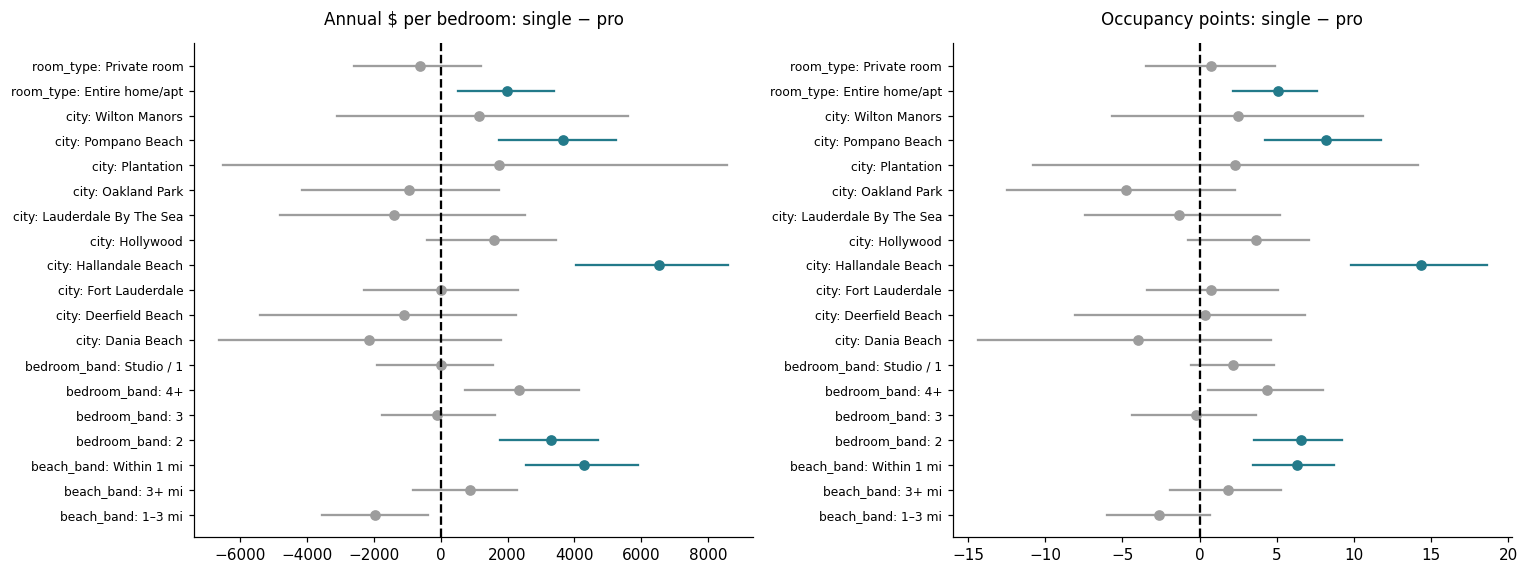

In [18]:
fig,axes=plt.subplots(1,2,figsize=(14,max(5,len(segments)/2*.28)))
for ax,outcome,label in zip(axes,['revenue_per_bedroom','occupancy_pct'],['Annual $ per bedroom: single − pro','Occupancy points: single − pro']):
    t=segments[segments.outcome.eq(outcome)].sort_values(['dimension','segment']).reset_index(drop=True)
    for i,r in t.iterrows():
        color=COLORS[0] if r.both_outcomes_supported else '#9D9D9D'
        ax.plot([r.low,r.high],[i,i],color=color); ax.plot(r.gap,i,'o',color=color)
    ax.set_yticks(np.arange(len(t)),t.dimension+': '+t.segment,fontsize=8); ax.axvline(0,color='black',ls='--'); ax.set_title(label,fontsize=11)
plt.tight_layout(); plt.show()

### C. Do segment gaps remain after adjustment?
For each eligible segment, fit the same physical-and-amenity controls within that segment (single and pro only), removing the categorical term that is constant for city or room-type subsets. Use host-clustered standard errors. Adjust p-values across this second family of tests as well. These checks describe whether raw opportunity segments survive the measured composition controls; they are not an independent validation sample. Compare confidence intervals and signs, not just significance labels.

In [19]:
adjusted_segments=[]
for dimension,segment in segments[['dimension','segment']].drop_duplicates().itertuples(index=False,name=None):
    z=model_data[model_data.host_tier.isin(['single','pro (10+)']) & model_data[dimension].eq(segment)].copy()
    z['single_flag']=z.host_tier.eq('single').astype(int)
    control=physical+' + '+amenity_terms
    if dimension in ['city','room_type']:
        control=' + '.join(t for t in control.split(' + ') if t!='C('+dimension+')')
    # Drop any remaining constant terms; remove unused categorical levels.
    for c in ['city','room_type','property_group']: z[c]=z[c].astype(str)
    control=' + '.join(t for t in control.split(' + ') if z[t[2:-1] if t.startswith('C(') else t].nunique()>1)
    for outcome in ['log_rpb','occupancy_pct']:
        m=clustered(outcome+' ~ single_flag + '+control,z); ci=m.conf_int().loc['single_flag']
        adjusted_segments.append({'dimension':dimension,'segment':segment,'outcome':outcome,'gap':m.params['single_flag'],'low':ci[0],'high':ci[1],'p':m.pvalues['single_flag'],'n':len(z)})
adjusted_segments=pd.DataFrame(adjusted_segments)
adjusted_segments['q']=multipletests(adjusted_segments.p,method='fdr_bh')[1]
display(adjusted_segments)
robust_flags=[]
for key in flags:
    a=adjusted_segments[(adjusted_segments.dimension==key[0])&(adjusted_segments.segment==key[1])]
    if len(a)==2 and ((a.low>0)&(a.q<.05)).all(): robust_flags.append(key)
print('Raw shortlist also supported after adjustment:',robust_flags)

Raw shortlist also supported after adjustment: []


,dimension,segment,outcome,gap,low,high,p,n,q
0,city,Dania Beach,log_rpb,-1.761,-2.824,-0.699,0.001,261,0.013
1,city,Dania Beach,occupancy_pct,-6.101,-12.921,0.720,0.079,261,0.251
2,city,Deerfield Beach,log_rpb,-0.642,-1.546,0.262,0.163,417,0.387
3,city,Deerfield Beach,occupancy_pct,1.210,-4.006,6.427,0.648,417,0.746
4,city,Fort Lauderdale,log_rpb,-0.659,-1.108,-0.209,0.004,2735,0.031
5,city,Fort Lauderdale,occupancy_pct,-1.852,-5.461,1.756,0.314,2735,0.525
6,city,Hallandale Beach,log_rpb,0.561,-0.374,1.495,0.238,1552,0.453
7,city,Hallandale Beach,occupancy_pct,5.807,1.608,10.006,0.007,1552,0.044
8,city,Hollywood,log_rpb,-0.155,-0.724,0.414,0.593,2644,0.704
9,city,Hollywood,occupancy_pct,0.041,-3.169,3.251,0.980,2644,0.980


### Where singles appear to win—and where evidence weakens
The raw, multiple-testing-adjusted shortlist includes **Hallandale Beach, Pompano Beach, entire homes, two-bedroom listings, and listings within one mile of the beach**. After within-segment adjustment, none is supported on both outcomes under the stricter rule.

**Hallandale Beach remains an occupancy lead worth investigating:** the adjusted single-host gap is about **+5.81 points** (95% CI 1.61 to 10.01; q≈0.044). Its adjusted revenue interval still crosses zero. Pompano Beach's raw advantage does not survive the controls. This distinction is the answer to “where independents beat pros”: some segments show raw advantages, one retains an occupancy signal, but the present evidence does not establish a segment with a robust advantage on both measures. Revenue also changes from arithmetic dollars in the raw scan to log(revenue + 1) in adjustment, so differences reflect both controls and the chosen estimand.

## 6. Stress-test the finding
### A. Alternative populations and outcome choices
The main sample includes zero and capped estimates. Sensitivities are deliberately separate estimands: established listings condition on survival; active-only and uncapped samples condition on outcomes; equal-host weighting changes the question from a typical listing to a typical account. Excluding the top 1% of revenue removes genuine high performers as well as possible errors. These are checks, not reasons to choose whichever result is most favorable.

In [20]:
checks={
    'Main':model_data,
    'Established only':model_data[model_data.listing_age_group.eq('established (1+ year)')],
    'Positive occupancy only':model_data[model_data.any_activity.eq(1)],
    'Below occupancy cap':model_data[model_data.occupancy_capped.eq(0)],
    'Original bedroom values':model_data[model_data.bedrooms_was_filled.eq(0)],
    'Entire homes only':model_data[model_data.room_type.eq('Entire home/apt')],
    'Drop top 1% revenue/bedroom':model_data[model_data.revenue_per_bedroom.le(model_data.revenue_per_bedroom.quantile(.99))],
    'Known short minimum stay':model_data[model_data.minimum_nights.lt(30)],
}
# Use the data's exact age label; the printed inventory makes the restriction auditable.
print('Age labels:',model_data.listing_age_group.value_counts().to_dict())
established_label=next(v for v in model_data.listing_age_group.unique() if 'established' in v.lower())
checks['Established only']=model_data[model_data.listing_age_group.eq(established_label)]
sensitivity=[]
for name,z in checks.items():
    for outcome in ['log_rpb','occupancy_pct']:
        formula=rhs['With amenities']
        if name=='Entire homes only': formula=formula.replace('C(room_type) + ','')
        m=clustered(outcome+' ~ '+formula,z)
        sensitivity.extend(tier_rows(m,outcome,name))
for outcome in ['log_rpb','occupancy_pct']:
    weights=1/model_data.groupby('host_id').id.transform('size')
    m=clustered(outcome+' ~ '+rhs['With amenities'],model_data,weights)
    sensitivity.extend(tier_rows(m,outcome,'Equal host weights'))
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity[sensitivity.contrast.eq('single vs pro')])

Age labels: {'established (1+ year)': 9197, 'first year': 3625, 'no reviews yet': 2876}


,outcome,model,contrast,estimate,low,high,p,n,R2
0,log_rpb,Main,single vs pro,-0.281,-0.570,0.009,0.057,15698,0.240
2,occupancy_pct,Main,single vs pro,0.047,-1.823,1.917,0.961,15698,0.191
4,log_rpb,Established only,single vs pro,-0.163,-0.520,0.194,0.372,9197,0.155
6,occupancy_pct,Established only,single vs pro,-0.122,-2.596,2.351,0.923,9197,0.151
8,log_rpb,Positive occupancy only,single vs pro,0.146,0.051,0.241,0.003,11367,0.163
10,occupancy_pct,Positive occupancy only,single vs pro,1.368,-0.722,3.458,0.199,11367,0.126
12,log_rpb,Below occupancy cap,single vs pro,-0.306,-0.600,-0.011,0.042,14891,0.234
14,occupancy_pct,Below occupancy cap,single vs pro,0.205,-1.313,1.723,0.791,14891,0.187
16,log_rpb,Original bedroom values,single vs pro,-0.285,-0.574,0.005,0.054,15680,0.240
18,occupancy_pct,Original bedroom values,single vs pro,0.048,-1.822,1.919,0.960,15680,0.190


### B. All-market accounts vs Broward portfolios vs consolidated operators
The main definition counts accounts across markets; local portfolios answer a different question. Substitute `broward_tier` and `operator_tier` into the same model and retain the same analytical listings. The raw side-by-side table makes reclassification visible. Account-clustered intervals are retained for comparability; operator consolidation may leave residual dependence across accounts.

In [21]:
tier_checks=[]
for definition in ['host_tier','broward_tier','operator_tier']:
    print(definition); display(summary(d,definition)[['listings','revenue_mean','revenue_median','occupancy_pct']])
    z=model_data.copy(); z['host_tier']=pd.Categorical(z[definition],categories=TIERS)
    for outcome in ['log_rpb','occupancy_pct']:
        m=clustered(outcome+' ~ '+rhs['With amenities'],z)
        tier_checks.extend(tier_rows(m,outcome,definition))
tier_checks=pd.DataFrame(tier_checks)
display(tier_checks)

host_tier
broward_tier
operator_tier


,listings,revenue_mean,revenue_median,occupancy_pct
host_tier,,,,
single,2919,"9,727.481","5,440.000",19.637
small (2-9),4747,"10,987.994","7,266.750",21.891
pro (10+),8032,"8,361.407","3,252.000",15.475


,listings,revenue_mean,revenue_median,occupancy_pct
broward_tier,,,,
single,3729,"9,845.788","5,560.000",19.747
small (2-9),5132,"10,837.897","6,872.500",21.306
pro (10+),6837,"8,099.798","2,995.000",14.999


,listings,revenue_mean,revenue_median,occupancy_pct
operator_tier,,,,
single,2918,"9,727.340","5,420.000",19.638
small (2-9),4705,"10,960.175","7,248.000",21.886
pro (10+),8075,"8,391.498","3,276.000",15.511


,outcome,model,contrast,estimate,low,high,p,n,R2
0,log_rpb,host_tier,single vs pro,-0.281,-0.570,0.009,0.057,15698,0.240
1,log_rpb,host_tier,small (2-9) vs pro,0.373,0.086,0.659,0.011,15698,0.240
2,occupancy_pct,host_tier,single vs pro,0.047,-1.823,1.917,0.961,15698,0.191
3,occupancy_pct,host_tier,small (2-9) vs pro,2.066,0.155,3.976,0.034,15698,0.191
4,log_rpb,broward_tier,single vs pro,-0.121,-0.449,0.207,0.468,15698,0.241
5,log_rpb,broward_tier,small (2-9) vs pro,0.558,0.221,0.895,0.001,15698,0.241
6,occupancy_pct,broward_tier,single vs pro,0.777,-1.274,2.827,0.458,15698,0.192
7,occupancy_pct,broward_tier,small (2-9) vs pro,2.710,0.602,4.818,0.012,15698,0.192
8,log_rpb,operator_tier,single vs pro,-0.288,-0.576,0.000,0.050,15698,0.240
9,log_rpb,operator_tier,small (2-9) vs pro,0.364,0.078,0.649,0.012,15698,0.240


**Robustness interpretation.** The single-host occupancy interval spans zero across the sample restrictions and all three host definitions. Small hosts retain a positive adjusted occupancy gap under the all-market, Broward-only, and consolidated-operator definitions. Revenue is more sensitive: singles have a positive log-revenue gap when only active listings remain, but not in the main all-listing sample. That is a selection-sensitive finding, not justification for discarding zero outcomes.

### C. Same survivors, fixed host classification
For listings observed in December, June, and September, fix host tier to its September value and compare estimated occupancy across snapshots. Restrict to listings in September's analysis sample and short-term at every observed date. Do not use March. This is a survivor-only descriptive trajectory: overlapping trailing-year windows and the fixed later host classification prevent a clean causal interpretation. December cannot support a revenue comparison.

,snapshot_date,fixed_tier,n,occupancy
0,2025-12-28,single,1933,0.210
1,2025-12-28,small (2-9),3317,0.234
2,2025-12-28,pro (10+),5156,0.163
3,2026-06-29,single,1933,0.236
4,2026-06-29,small (2-9),3317,0.264
5,2026-06-29,pro (10+),5156,0.192
6,2026-09-22,single,1933,0.239
7,2026-09-22,small (2-9),3317,0.268
8,2026-09-22,pro (10+),5156,0.198


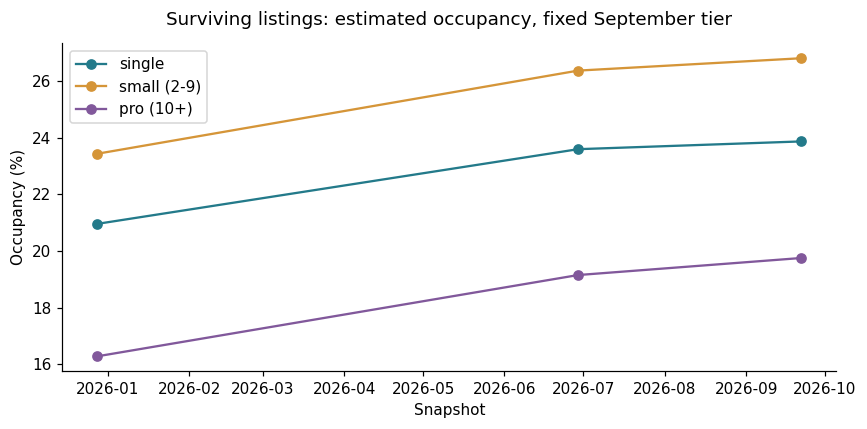

In [22]:
ids=d.loc[d.in_panel.eq(1),'id']
panel=listings[listings.id.isin(ids)&listings.snapshot_date.isin([DEC,JUN,SEP])].copy()
valid_ids=panel.groupby('id').minimum_nights.apply(lambda s:s.notna().all() and s.lt(30).all())
panel=panel[panel.id.isin(valid_ids[valid_ids].index)]
fixed=d.set_index('id').host_tier
panel['fixed_tier']=panel.id.map(fixed)
trajectory=panel.groupby(['snapshot_date','fixed_tier'],observed=True).agg(n=('id','size'),occupancy=('occupancy_rate_l365d','mean')).reset_index()
display(trajectory)
fig,ax=plt.subplots(figsize=(8,4))
for tier,color in zip(TIERS,COLORS):
    t=trajectory[trajectory.fixed_tier.eq(tier)]
    ax.plot(t.snapshot_date,t.occupancy*100,'o-',label=tier,color=color)
ax.set(title='Surviving listings: estimated occupancy, fixed September tier',ylabel='Occupancy (%)',xlabel='Snapshot'); ax.legend(); plt.tight_layout(); plt.show()

### D. Calendar cross-check: unavailability is not occupancy
Use October–December 2026, all observed from the September scrape, with ≥25 calendar days per listing-month. Match the same listing IDs across all three months so changing composition does not drive the trend. Aggregate unavailable days / observed days rather than averaging partial months. Fully blocked listing-months are shown separately and then excluded in a check.

This is a **forward calendar signal**, not the trailing-year target. Nights can be booked, blocked for owner use, or not yet opened. A contradiction with estimated occupancy therefore challenges a simple demand story; agreement cannot validate actual bookings.

listings  unavailable    days  fully_blocked_share  \
month   host_tier                                                         
2026-10 single           2919        25174   90489                0.098   
        small (2-9)      4747        44801  147157                0.099   
        pro (10+)        8032        73141  248992                0.057   
2026-11 single           2919        21659   87570                0.094   
        small (2-9)      4747        36346  142410                0.101   
        pro (10+)        8032        53643  240960                0.061   
2026-12 single           2919        27750   90489                0.097   
        small (2-9)      4747        44437  147157                0.105   
        pro (10+)        8032        54333  248992                0.076   

                     unavailable_pct  
month   host_tier                     
2026-10 single                27.820  
        small (2-9)           30.444  
        pro (10+)             29.375  
2026-11 single                24.733  
        small (2-9)           25.522  
        pro (10+)             22.262  
2026-12 single                30.667  
        small (2-9)           30.197  
        pro (10+)             21.821

listings  unavailable    days  fully_blocked_share  \
month   host_tier                                                         
2026-10 single           2633        16308   81623                0.000   
        small (2-9)      4279        30293  132649                0.000   
        pro (10+)        7578        59067  234918                0.000   
2026-11 single           2646        13469   79380                0.000   
        small (2-9)      4268        21976  128040                0.000   
        pro (10+)        7544        39003  226320                0.000   
2026-12 single           2637        19008   81747                0.000   
        small (2-9)      4250        29030  131750                0.000   
        pro (10+)        7424        35485  230144                0.000   

                     unavailable_pct  
month   host_tier                     
2026-10 single                19.980  
        small (2-9)           22.837  
        pro (10+)             25.144  
2026-11 single                16.968  
        small (2-9)           17.163  
        pro (10+)             17.234  
2026-12 single                23.252  
        small (2-9)           22.034  
        pro (10+)             15.419

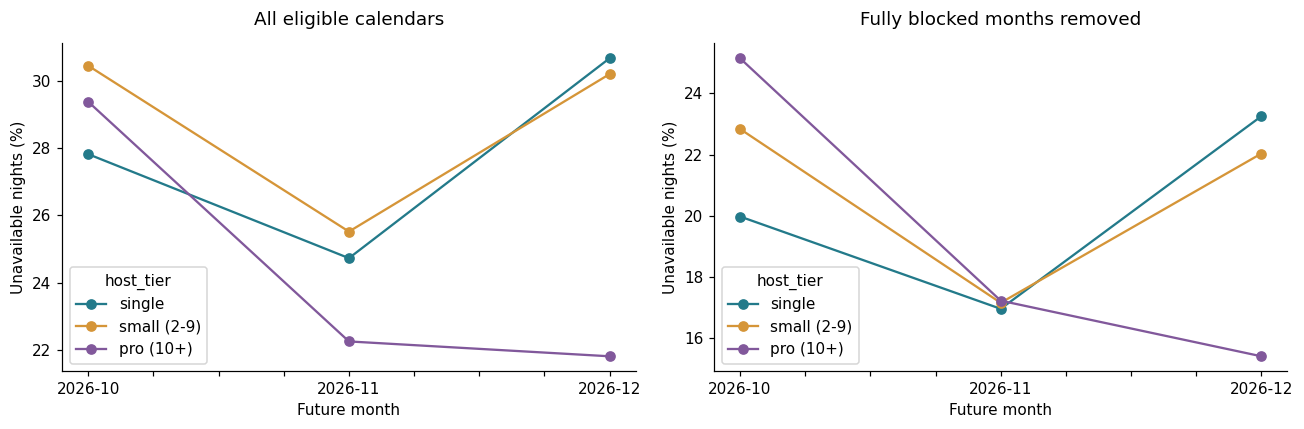

In [23]:
cm=pd.read_parquet(DATA/'calendar_monthly.parquet')
cm['month']=cm.month.astype(str)
cal=cm[cm.snapshot_date.eq(SEP)&cm.month.isin(['2026-10','2026-11','2026-12'])&cm.days.ge(25)].copy()
cal=cal.merge(d[['id','host_tier']],left_on='listing_id',right_on='id',how='inner',validate='many_to_one')
assert not cal.duplicated(['listing_id','month']).any()
complete=cal.groupby('listing_id').month.nunique(); cal=cal[cal.listing_id.isin(complete[complete.eq(3)].index)]
cal['fully_blocked']=cal.unavailable_days.eq(cal.days)
def calendar_summary(z):
    a=z.groupby(['month','host_tier'],observed=True).agg(listings=('listing_id','nunique'),unavailable=('unavailable_days','sum'),days=('days','sum'),fully_blocked_share=('fully_blocked','mean'))
    a['unavailable_pct']=100*a.unavailable/a.days
    return a
calendar_all=calendar_summary(cal); calendar_partial=calendar_summary(cal[~cal.fully_blocked])
display(calendar_all); display(calendar_partial)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,t,title in zip(axes,[calendar_all,calendar_partial],['All eligible calendars','Fully blocked months removed']):
    t.unavailable_pct.unstack('host_tier').reindex(columns=TIERS).plot(ax=ax,marker='o',color=COLORS)
    ax.set(title=title,ylabel='Unavailable nights (%)',xlabel='Future month')
plt.tight_layout(); plt.show()

**Calendar and panel interpretation.** The survivor panel retains the raw ordering—small, single, pro—but conditions on listings that remained in the data. The calendar check is less uniform: after fully blocked months are removed, pros have the highest October unavailability, while singles have the highest December unavailability. This is inconsistent with a blanket claim that single hosts always fill more nights. Different booking lead times and owner blocks can explain the differences; these forward calendars do not verify the trailing-year occupancy estimate.

## 7. What the evidence says for an independent host
The following synthesis is computed from this run so the conclusions remain tied to the displayed estimates. “Supported” means the specified intervals and multiple-testing rule are met; it does not mean a causal effect has been demonstrated.

In [24]:
r=coef[(coef.outcome=='occupancy_pct')&(coef.model=='With amenities')&(coef.contrast=='single vs pro')].iloc[0]
v=coef[(coef.outcome=='log_rpb')&(coef.model=='With amenities')&(coef.contrast=='single vs pro')].iloc[0]
shortlist='; '.join(f'{a}: {b}' for a,b in robust_flags) or 'None meets both raw and adjusted evidence rules.'
imp_text='; '.join(f"{outcome}: {', '.join(t.head(3).feature)}" for outcome,t in importances.items())
sens=sensitivity[(sensitivity.contrast=='single vs pro')&(sensitivity.outcome=='occupancy_pct')]
display(Markdown(f"""
### Findings
1. **Portfolio size is informative, but the ranking is not simply 'bigger is better'.** Median estimated annual revenue per bedroom: single **${raw.loc['single','revenue_median']:,.0f}**, small **${raw.loc['small (2-9)','revenue_median']:,.0f}**, pro **${raw.loc['pro (10+)','revenue_median']:,.0f}**. Mean occupancy: **{raw.loc['single','occupancy_pct']:.1f}%**, **{raw.loc['small (2-9)','occupancy_pct']:.1f}%**, and **{raw.loc['pro (10+)','occupancy_pct']:.1f}%**, respectively.
2. **After measured listing differences:** single minus pro is **{r.estimate:+.2f} occupancy points** (95% CI {r.low:+.2f} to {r.high:+.2f}) and **{v.estimate:+.3f} log points in revenue + 1** (95% CI {v.low:+.3f} to {v.high:+.3f}). These are conditional associations.
3. **Where the evidence is strongest:** {shortlist} These are screening segments, not guaranteed winning investments. Review their group sizes and the common-support table before using them.
4. **Predictive signals:** the three highest holdout permutation rankings are {imp_text}. Rankings describe information used by these models; amenity coefficients and uncertainty in Section 3 help interpret direction.
5. **Sensitivity:** single-minus-pro occupancy estimates range from **{sens.estimate.min():+.2f} to {sens.estimate.max():+.2f} points** across the stated sample/weighting checks. Restrictions change the target population, so this range is not a confidence interval.
"""))
display(test_results)
print('Summary values above are generated from this run, not manually typed assumptions.')

Summary values above are generated from this run, not manually typed assumptions.



### Findings
1. **Portfolio size is informative, but the ranking is not simply 'bigger is better'.** Median estimated annual revenue per bedroom: single **$5,440**, small **$7,267**, pro **$3,252**. Mean occupancy: **19.6%**, **21.9%**, and **15.5%**, respectively.
2. **After measured listing differences:** single minus pro is **+0.05 occupancy points** (95% CI -1.82 to +1.92) and **-0.281 log points in revenue + 1** (95% CI -0.570 to +0.009). These are conditional associations.
3. **Where the evidence is strongest:** None meets both raw and adjusted evidence rules. These are screening segments, not guaranteed winning investments. Review their group sizes and the common-support table before using them.
4. **Predictive signals:** the three highest holdout permutation rankings are log_rpb: self_checkin, city, mi_to_stadium; occupancy_pct: mi_to_beach_approx, self_checkin, mi_to_stadium. Rankings describe information used by these models; amenity coefficients and uncertainty in Section 3 help interpret direction.
5. **Sensitivity:** single-minus-pro occupancy estimates range from **-0.12 to +1.37 points** across the stated sample/weighting checks. Restrictions change the target population, so this range is not a confidence interval.


,outcome,chosen,test_mae,test_R2,baseline_mae
0,log_rpb,Random forest,2.834,0.233,3.509
1,occupancy_pct,Random forest,13.539,0.238,17.102


### Implications for a host or client

- **Benchmark against the same product.** Compare city, room type, bedrooms, and beach access before comparing portfolios. Use the supported segment shortlist as a place to investigate actual local competitors; do not select a market from a raw ranking alone.
- **Treat small operators separately.** A 2–9 listing host may combine local attention and repeatable operations. Combining small and single accounts can conceal their different performance.
- **Use occupancy and revenue together.** More occupied nights can coexist with weak dollars per bedroom; a smaller denominator can make a studio look efficient without producing high total income. Neither outcome measures profit, financing costs, cleaning costs, or labor.
- **Evaluate amenities as hypotheses.** A pool, parking, or self check-in can correlate with performance because it marks a different property class. Compare installation/operating cost and run a real before/after or randomized operational test before claiming return on investment.
- **Use reputation to monitor service, not to claim cause.** Ratings and Superhost are useful signals on reviewed listings, but this notebook cannot show that receiving a badge creates additional demand.